# Sales Insights Analysis — D2C Spice Brand

**Business question:** Where does revenue come from, how much does the festive season matter, and which channels should the brand invest in for 2026?

> The dataset is **synthetic** (generated by `src/generate_data.py`) and modelled on a real-world D2C food brand: festive demand spikes, marketplace vs. own-website sales, discounts and returns. The brand "Tadka & Co." is fictional.

In [1]:
import sqlite3
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})
IMG = Path("images"); IMG.mkdir(exist_ok=True)

orders = pd.read_csv("data/orders.csv", parse_dates=["order_date"])
products = pd.read_csv("data/products.csv")
print(f"{len(orders):,} line items | {orders.order_id.nunique():,} orders | "
      f"{orders.order_date.min():%d %b %Y} to {orders.order_date.max():%d %b %Y}")
orders.head()

48,488 line items | 27,658 orders | 01 Jan 2024 to 31 Dec 2025


,order_id,order_date,channel,city,region,sku,quantity,unit_price,discount_pct,revenue,is_returned
0,ORD100001,2024-01-01,Website,Bengaluru,South,SKU10,2,799,0.071,1485.32,False
1,ORD100002,2024-01-01,Flipkart,Lucknow,North,SKU05,1,145,0.161,121.65,True
2,ORD100002,2024-01-01,Flipkart,Lucknow,North,SKU07,2,89,0.149,151.57,False
3,ORD100002,2024-01-01,Flipkart,Lucknow,North,SKU03,1,85,0.187,69.13,False
4,ORD100003,2024-01-01,Website,Gurugram,North,SKU01,1,95,0.093,86.17,False


## 1. Data quality checks

In [2]:
checks = {
    "missing values": int(orders.isna().sum().sum()),
    "duplicate rows": int(orders.duplicated().sum()),
    "negative revenue": int((orders.revenue < 0).sum()),
    "unknown SKUs": int((~orders.sku.isin(products.sku)).sum()),
    "discount > 35%": int((orders.discount_pct > 0.35).sum()),
}
pd.Series(checks, name="count").to_frame()

,count
missing values,0
duplicate rows,0
negative revenue,0
unknown SKUs,0
discount > 35%,0


## 2. SQL analysis
The business questions are written in SQL (`sql/queries.sql`) and run against an in-memory SQLite database.

In [3]:
con = sqlite3.connect(":memory:")
orders.assign(order_date=orders.order_date.dt.strftime("%Y-%m-%d"),
              is_returned=orders.is_returned.astype(int)).to_sql("orders", con, index=False)
products.to_sql("products", con, index=False)

# split the .sql file into named queries
queries, name = {}, None
for line in Path("sql/queries.sql").read_text().splitlines():
    if line.startswith("-- name:"):
        name = line.split(":", 1)[1].strip(); queries[name] = ""
    elif name:
        queries[name] += line + "\n"
q = lambda n: pd.read_sql(queries[n], con)
list(queries)

['monthly_revenue', 'channel_performance', 'top_products', 'region_yoy']

### Monthly net revenue

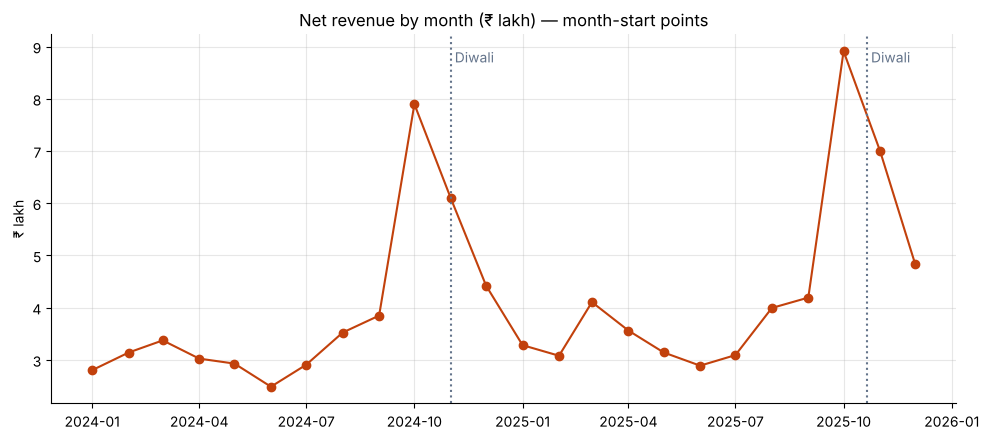

2024: ₹46.4 lakh | 2025: ₹52.1 lakh | growth 12.1%


In [4]:
monthly = q("monthly_revenue")
monthly["month"] = pd.to_datetime(monthly["month"])
fig, ax = plt.subplots()
ax.plot(monthly.month, monthly.net_revenue / 1e5, marker="o", color="#c2410c")
for dt in ["2024-11-01", "2025-10-21"]:
    ax.axvline(pd.Timestamp(dt), color="#64748b", ls=":", lw=1.5)
    ax.text(pd.Timestamp(dt), ax.get_ylim()[1] * 0.97, " Diwali", color="#64748b", va="top")
ax.set_title("Net revenue by month (₹ lakh) — month-start points")
ax.set_ylabel("₹ lakh")
plt.tight_layout(); plt.savefig(IMG / "monthly_revenue.png", dpi=120); plt.show()

yearly = monthly.groupby(monthly.month.dt.year).net_revenue.sum()
print(f"2024: ₹{yearly[2024]/1e5:.1f} lakh | 2025: ₹{yearly[2025]/1e5:.1f} lakh | growth {100*(yearly[2025]/yearly[2024]-1):.1f}%")

### Channel scorecard

In [5]:
channels = q("channel_performance")
channels

,channel,gross_revenue,revenue_share_pct,avg_order_value,avg_discount_pct,return_rate_pct
0,Amazon,4415020.0,42.4,373.0,12.6,5.8
1,Website,2426946.0,23.3,395.0,8.7,2.9
2,Flipkart,2260151.0,21.7,358.0,15.7,7.9
3,Instagram,1310866.0,12.6,389.0,10.7,4.3


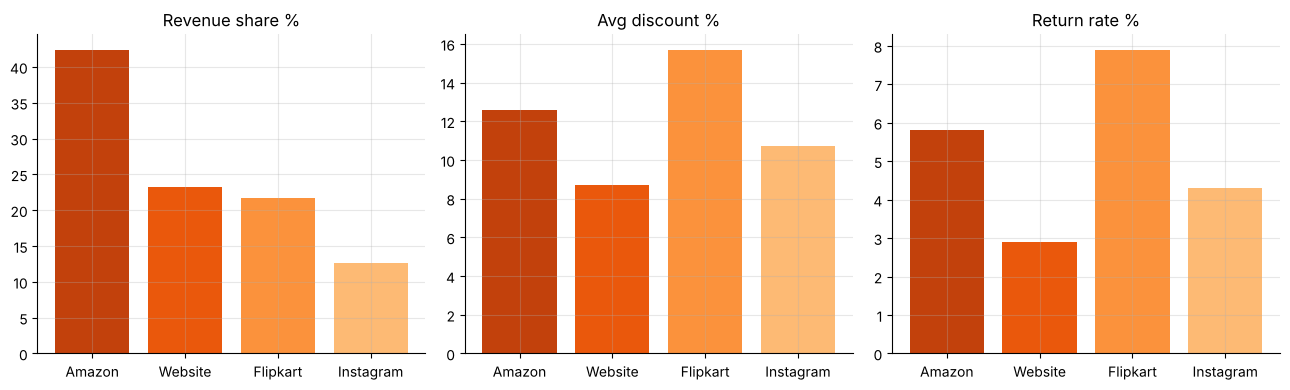

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
colors = ["#c2410c", "#ea580c", "#fb923c", "#fdba74"]
for ax, col, title in zip(axes, ["revenue_share_pct", "avg_discount_pct", "return_rate_pct"],
                          ["Revenue share %", "Avg discount %", "Return rate %"]):
    ax.bar(channels.channel, channels[col], color=colors)
    ax.set_title(title)
plt.tight_layout(); plt.savefig(IMG / "channel_scorecard.png", dpi=120); plt.show()

### Channel mix shift, 2024 vs 2025

In [7]:
mix = (orders.assign(year=orders.order_date.dt.year)
       .pivot_table(index="year", columns="channel", values="revenue", aggfunc="sum"))
mix = (mix.div(mix.sum(axis=1), axis=0) * 100).round(1)
mix

channel,Amazon,Flipkart,Instagram,Website
year,,,,
2024,46.1,22.7,10.1,21.1
2025,39.1,20.8,14.8,25.3


### Top products

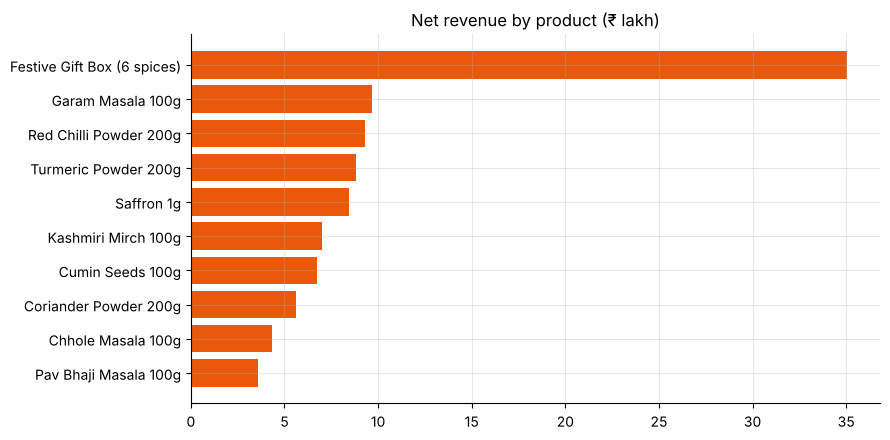

,product_name,category,units,net_revenue
0,Festive Gift Box (6 spices),Gift Packs,5349,3505205.0
1,Garam Masala 100g,Blended Masala,8015,967361.0
2,Red Chilli Powder 200g,Basic Spices,10148,929509.0
3,Turmeric Powder 200g,Basic Spices,11192,883111.0
4,Saffron 1g,Premium,2931,843578.0
5,Kashmiri Mirch 100g,Premium,4811,700412.0
6,Cumin Seeds 100g,Whole Spices,6707,673438.0
7,Coriander Powder 200g,Basic Spices,7955,561241.0
8,Chhole Masala 100g,Blended Masala,5258,430835.0
9,Pav Bhaji Masala 100g,Blended Masala,4844,356785.0


In [8]:
top = q("top_products")
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(top.product_name[::-1], top.net_revenue[::-1] / 1e5, color="#ea580c")
ax.set_title("Net revenue by product (₹ lakh)")
plt.tight_layout(); plt.savefig(IMG / "top_products.png", dpi=120); plt.show()
top

## 3. How much does Diwali matter?

In [9]:
diwali = {2024: pd.Timestamp("2024-11-01"), 2025: pd.Timestamp("2025-10-21")}
orders["days_to_diwali"] = orders.apply(lambda r: (diwali[r.order_date.year] - r.order_date).days, axis=1)
orders["festive"] = orders.days_to_diwali.between(0, 21)

daily = orders.groupby(["order_date", "festive"]).revenue.sum().reset_index()
avg = daily.groupby("festive").revenue.mean()
uplift = avg[True] / avg[False] - 1
gift = orders[orders.sku == "SKU10"]
gift_share = gift[gift.festive].revenue.sum() / gift.revenue.sum()
festive_share = orders[orders.festive].revenue.sum() / orders.revenue.sum()
print(f"Avg daily revenue in the 3 weeks before Diwali is {uplift:.0%} higher than other days.")
print(f"Those ~6 weeks (out of 104) bring {festive_share:.0%} of total revenue.")
print(f"{gift_share:.0%} of Festive Gift Box revenue comes from the Diwali window.")

Avg daily revenue in the 3 weeks before Diwali is 154% higher than other days.
Those ~6 weeks (out of 104) bring 14% of total revenue.
26% of Festive Gift Box revenue comes from the Diwali window.


## 4. Regional growth

In [10]:
q('region_yoy')

,region,rev_2024,rev_2025,yoy_growth_pct
0,East,540641.0,622297.0,15.1
1,North,1908272.0,2136722.0,12.0
2,South,1222579.0,1365482.0,11.7
3,West,1237062.0,1379928.0,11.5


## 5. Simple 2026 forecast
A seasonal model: average month-of-year pattern × the 2025 level, grown at the observed rate. Good enough for planning stock; a real version would use Prophet or SARIMA.

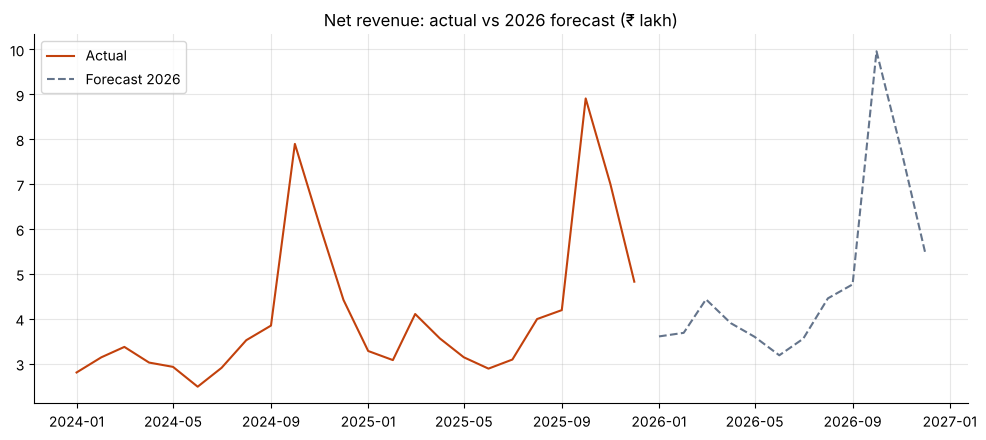

Forecast 2026 net revenue: ₹58.4 lakh (peak month: October)


In [11]:
m = monthly.set_index("month").net_revenue
growth = m["2025"].sum() / m["2024"].sum()
seasonal = m.groupby(m.index.month).mean() / m.mean()
base_2026 = m["2025"].mean() * growth
forecast = pd.Series([base_2026 * seasonal[i] for i in range(1, 13)],
                     index=pd.date_range("2026-01-01", periods=12, freq="MS"))
fig, ax = plt.subplots()
ax.plot(m.index, m / 1e5, label="Actual", color="#c2410c")
ax.plot(forecast.index, forecast / 1e5, "--", label="Forecast 2026", color="#64748b")
ax.set_title("Net revenue: actual vs 2026 forecast (₹ lakh)"); ax.legend()
plt.tight_layout(); plt.savefig(IMG / "forecast_2026.png", dpi=120); plt.show()
print(f"Forecast 2026 net revenue: ₹{forecast.sum()/1e5:.1f} lakh (peak month: {forecast.idxmax():%B})")

## 6. Recommendations

1. **Plan stock and ads around Diwali.** A large share of the year's revenue lands in a few weeks. Build Gift Box and Saffron inventory by mid-September.
2. **Keep growing the Website and Instagram channels.** They have the lowest discounts and return rates, so each sale keeps more margin than on the marketplaces.
3. **Look at Flipkart's return rate.** It has the highest discounts *and* returns. Check packaging and listing accuracy before spending more there.
4. **Use the Gift Box as a festive lead product**, then bring those buyers back with basic-spice refills over the rest of the year.